<a href="https://colab.research.google.com/github/AlejandroMev/Data-Scientist/blob/main/Alejandro_Mej%C3%ADa_Villa_Formato_Reto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Automatic ML - DS_C8_SC1**

---

**Reto: Predicción de candidatos elegibles para promoción laboral**

NOMBRE DEL PARTICIPANTE: ------------------------------(Alejandro Mejía Villa)------------------------------

In [ ]:
# Es importante instalar todas las librerías inicialmente, porque Colab pide reiniciar el entorno de ejecución
# Cuando esto ocurra, es NECESARIO volver a ejecutar esta misma celda, ya que el reinicio borra las librerías instaladas en memoria
!pip install fg-data-profiling
!pip install sweetviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.5/400.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.3/106.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 37.8 MB/s eta 0:00:00


In [ ]:
# Por un problema de incompatibilidad con Python 3.12, se sobrescribe el archivo __init__.py de PyCaret
# Con esto se desactiva la validación de versión y permite su uso en este entorno
!pip install pycaret

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 974.9 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 2.8 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of category-encoders to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of pmdarima to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of pyod to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.3/59.3 kB 1.6 MB/s eta 0:00:00

In [ ]:
content = '''import sys
from pycaret.utils._show_versions import show_versions

version_ = "3.3.2"
__version__ = version_
__all__ = ["show_versions", "__version__"]

if sys.version_info < (3, 9):
    raise RuntimeError(
        "Pycaret only supports python 3.9, 3.10, 3.11. Your actual Python version: ",
        sys.version_info,
        "Please UPGRADE your Python version.",
    )
elif False:
    pass  # patched for 3.12
'''

with open("/usr/local/lib/python3.12/dist-packages/pycaret/__init__.py", "w") as f:
    f.write(content)

print("Listo ✅")

Listo ✅


1.	Descarga el archivo: EmployeePromotion.csv y guarda, en un dataframe (`info`), todos sus registros.

In [ ]:
import pandas as pd

In [ ]:
# Aquí debes leer el archivo para crear el dataframe info
info = pd.read_csv('/content/EmployeePromotion.csv')
info.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0


2. Realiza un análisis exploratorio de datos con la plataforma de AutoEDA ydata Profiling. En la sección de Overview incluye una pestaña `Dataset` con la descripción del conjunto de datos y tu nombre como autor. En una pestaña `Variables` coloca el significado de las columnas.

* **IMPORTANTE**: El reporte debe quedar incrustado en la propia libreta, NO en un archivo html por separado.

In [ ]:
from data_profiling import ProfileReport

In [ ]:
# Genera el reporte con ydata Profiling
ydata_report = ProfileReport(info,
 dataset={
        'description': "Almacena la información personal de los trabajadores",
        'author': 'Alejandro Mejía Villa'
  },
  variables={
  'descriptions': {"employee_id": "id_empleado", "department": "Departamento_de_empleado",
  "region": "Región_de_empleo",	"education": "Nivel_educativo",	"gender": "Género_del_empleado",
  "recruitment_channel": "Canal_de_reclutamiento",	"no_of_trainings": "no._de_entrenamientos",
  "age": "Edad",	"previous_year_rating": "Calif_del_año_pasado ",
  "length_of_service": "Años_de_servicio",	"awards_won?": "¿Ganó_algún_premio?",
  "avg_training_score": "Promedio_de_evaluación_del_entrenamiento",
  "is_promoted": "¿Recomendado_para_promoción?"}
    },
    interactions=None,
    correlations=None)

ydata_report.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:02<00:00,  4.95it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

3. Con la plataforma SweetViz divide el conjunto utilizando la variable `gender` como booleana para comparar las características de los subconjuntos resultantes.

* **IMPORTANTE**: El reporte debe quedar incrustado en la propia libreta, NO en un archivo html por separado.

In [ ]:
import sweetviz as sv

                                             |          | [  0%]   00:00 -> (? left)


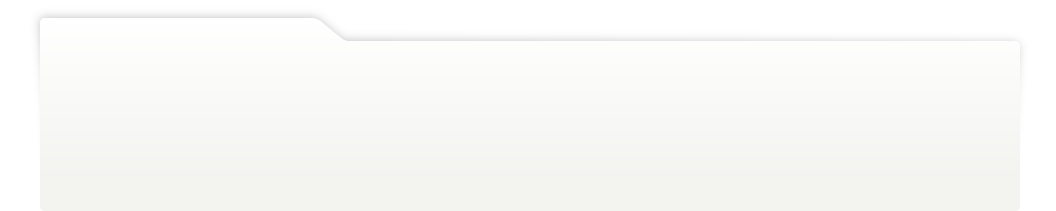
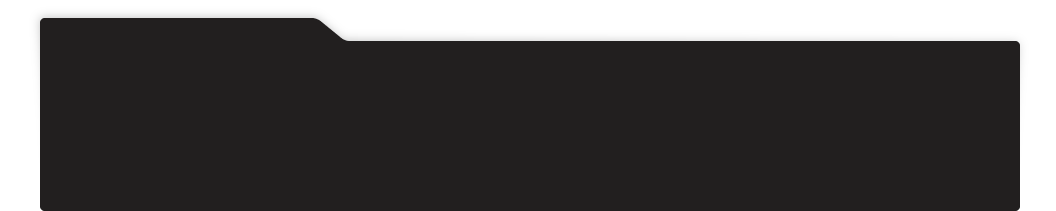
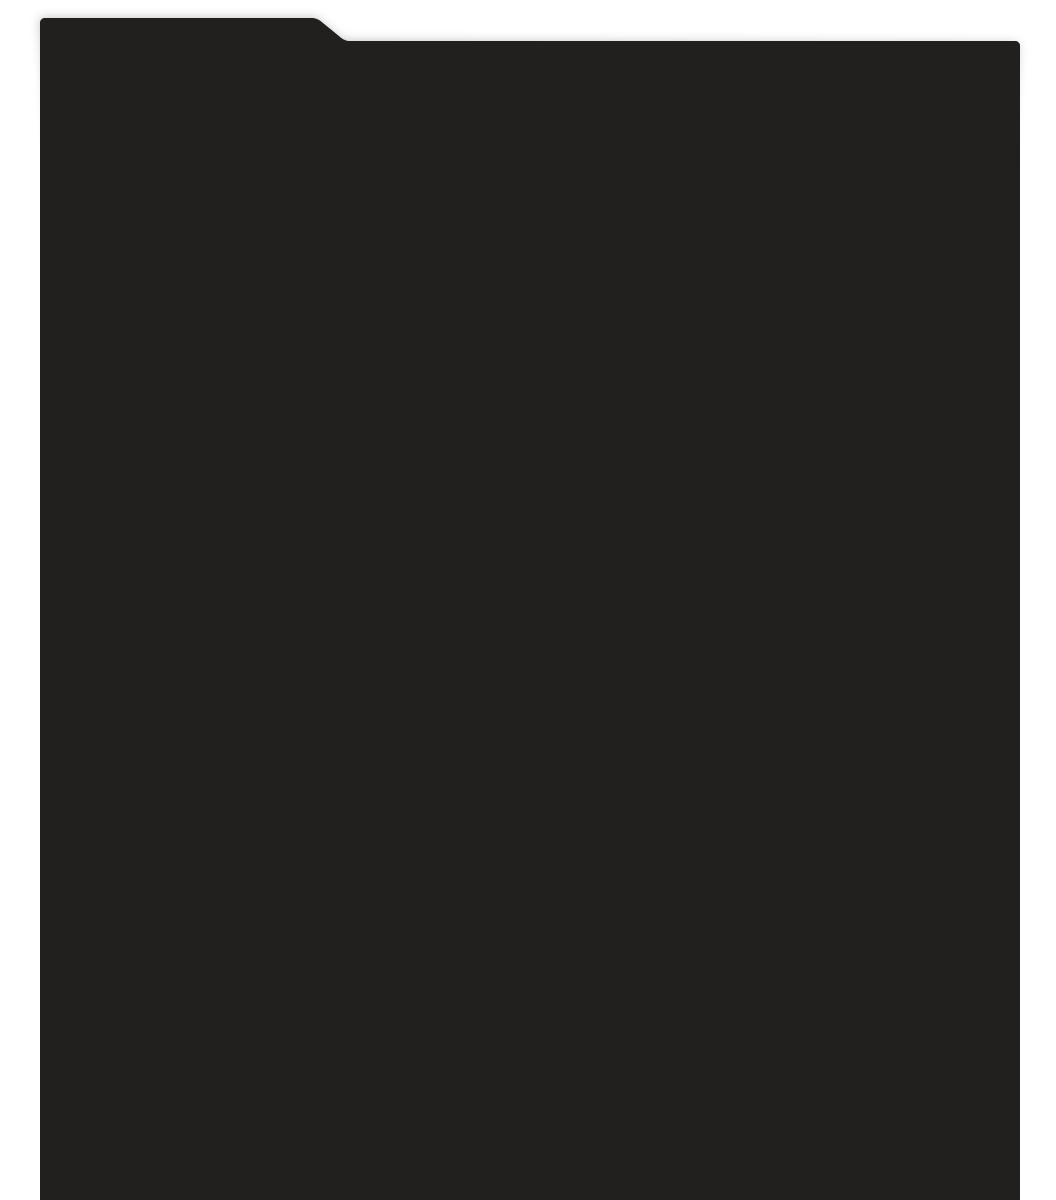
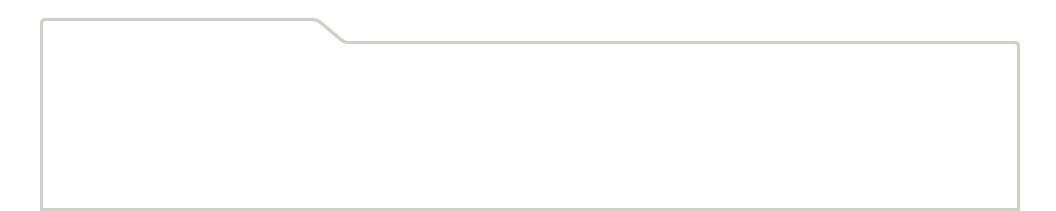
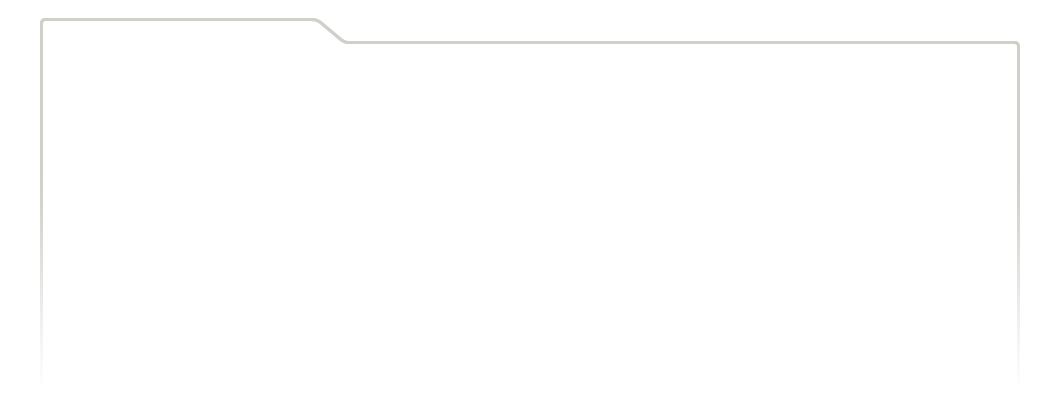
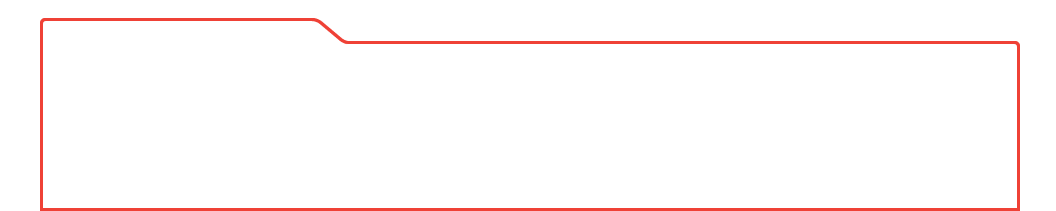
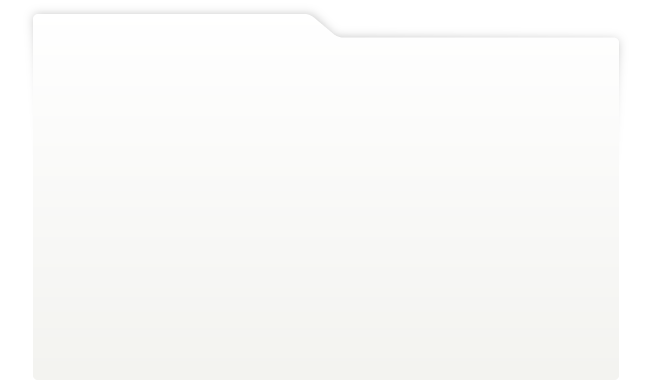
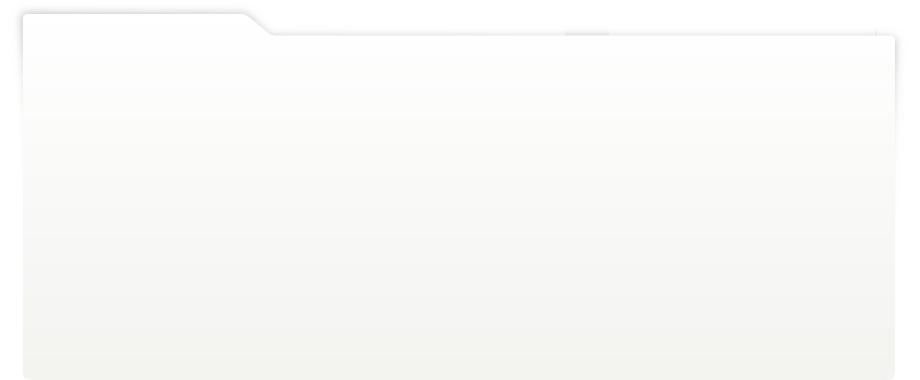
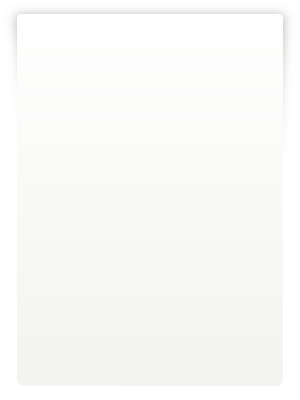
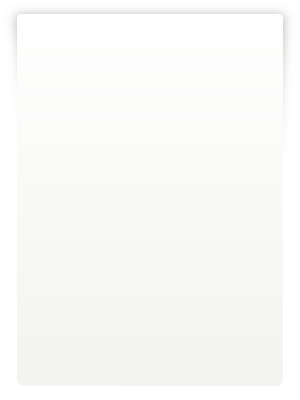
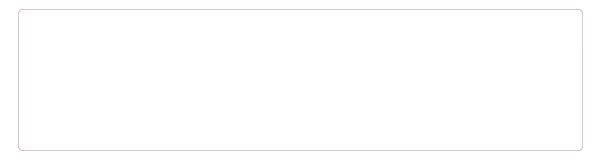
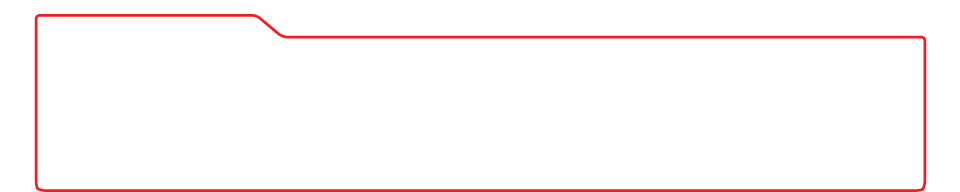
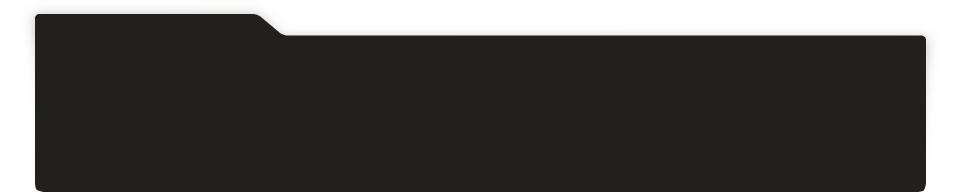
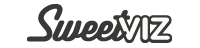
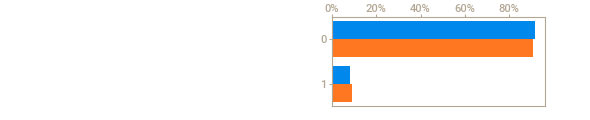
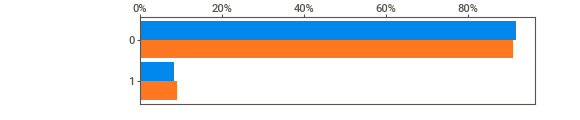
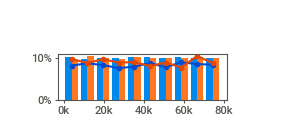
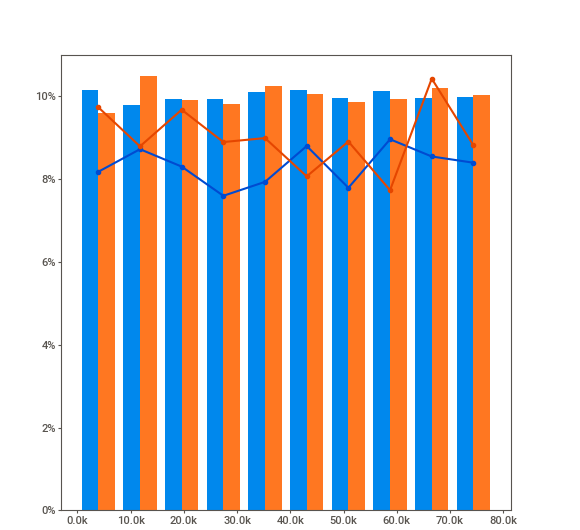
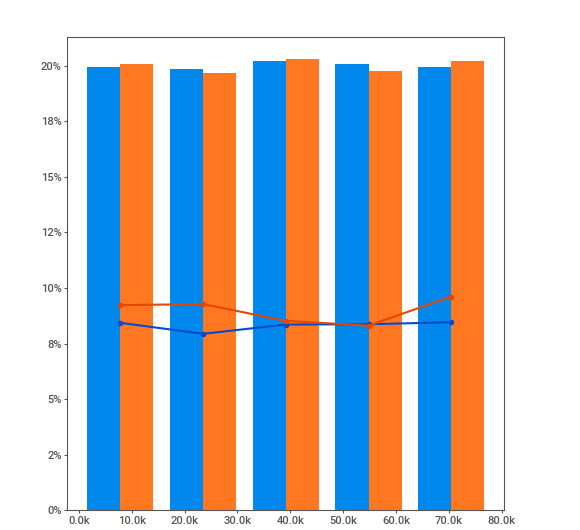
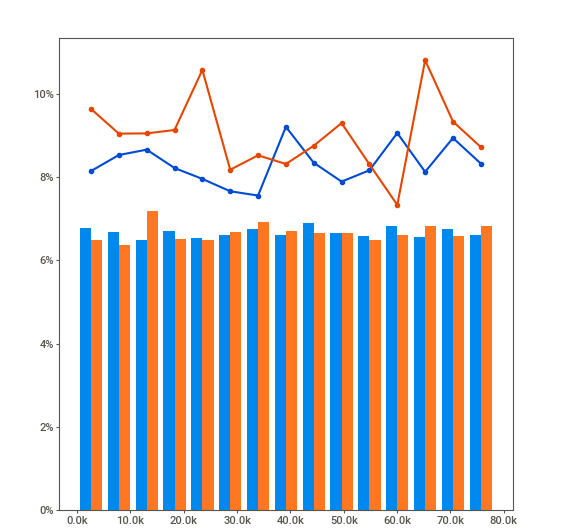
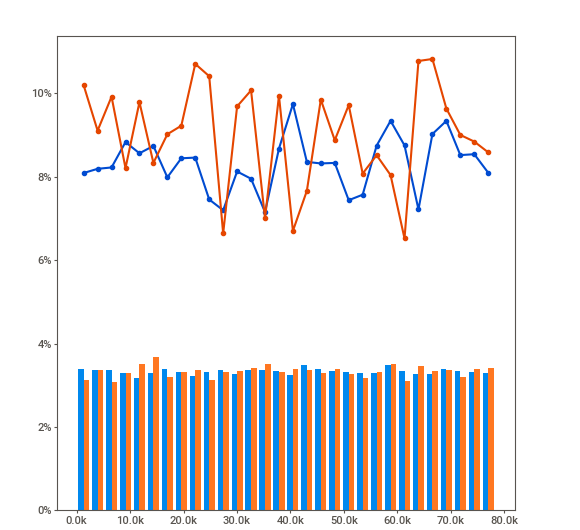
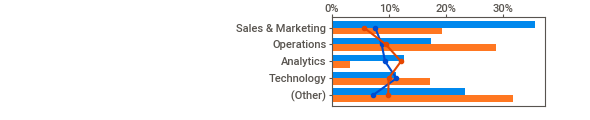
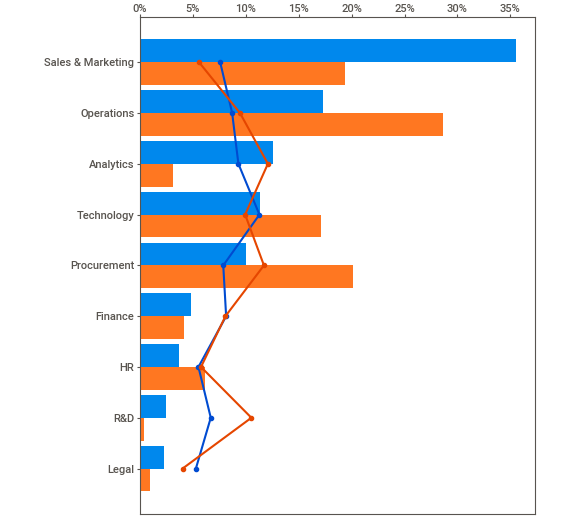
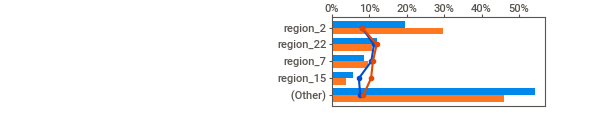
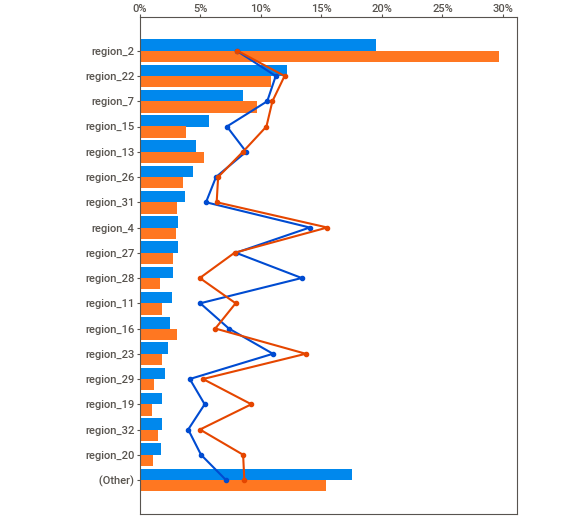
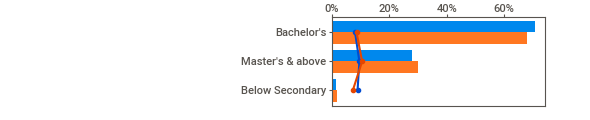
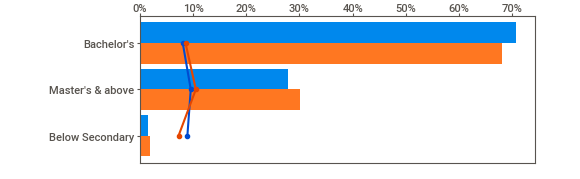
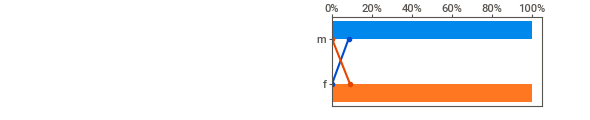
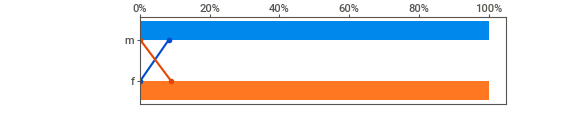
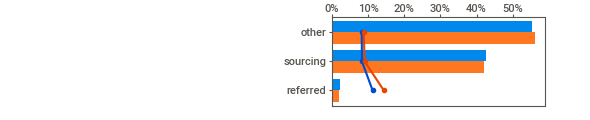
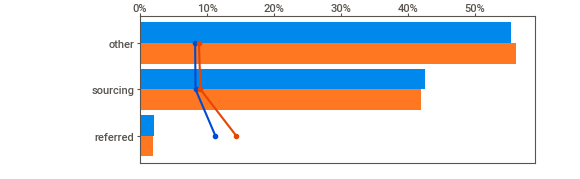
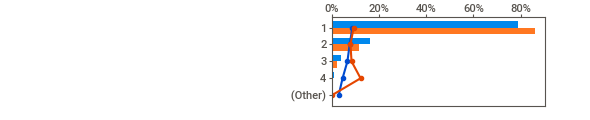
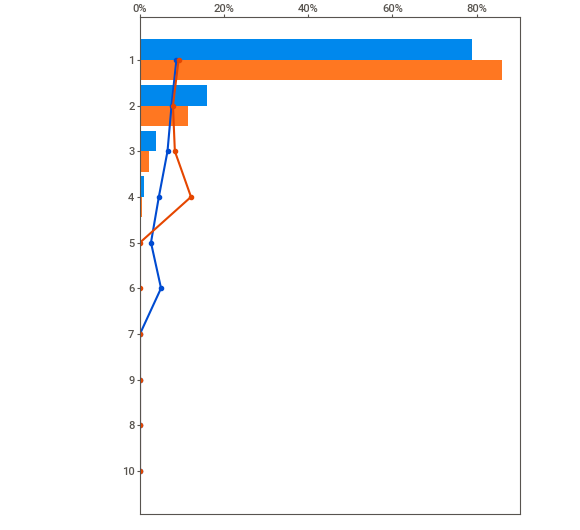
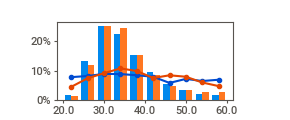
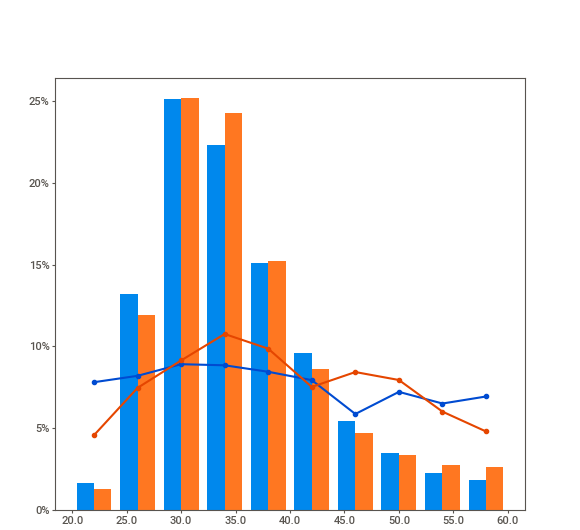
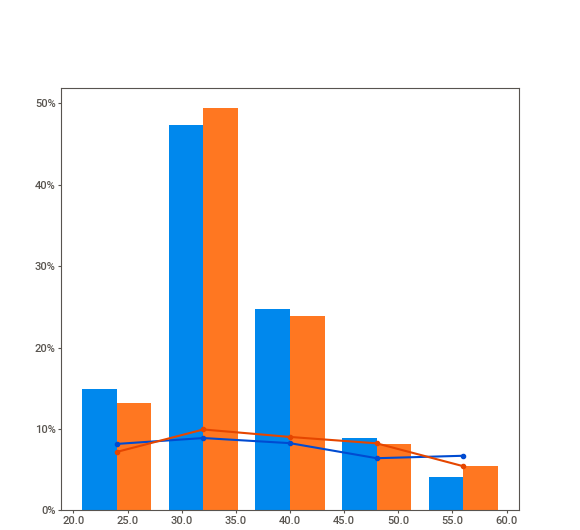
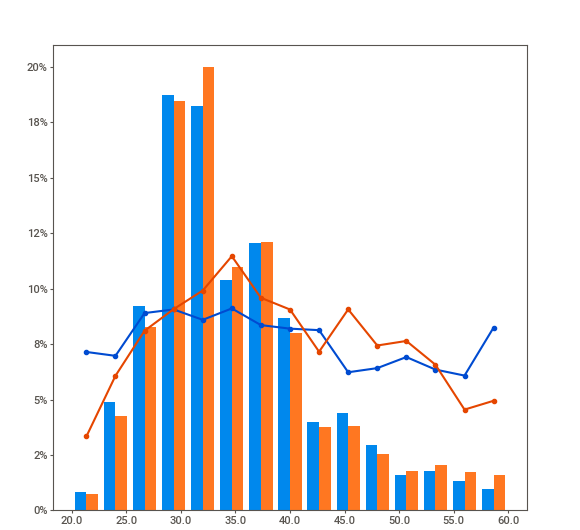
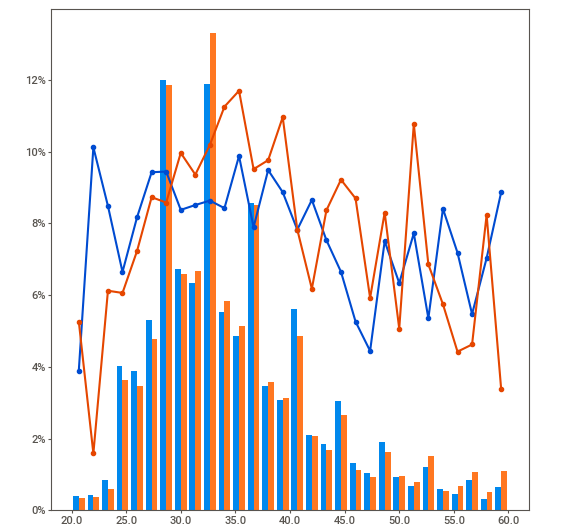
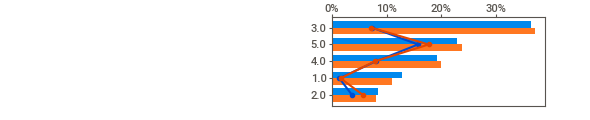
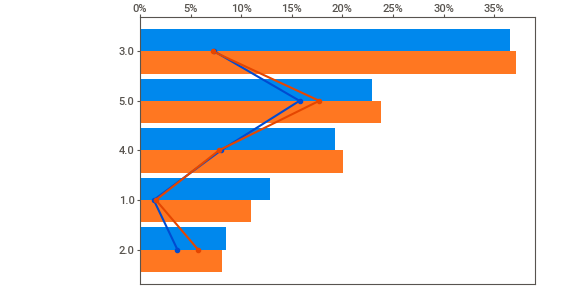
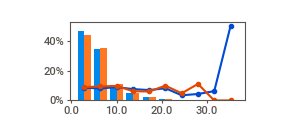
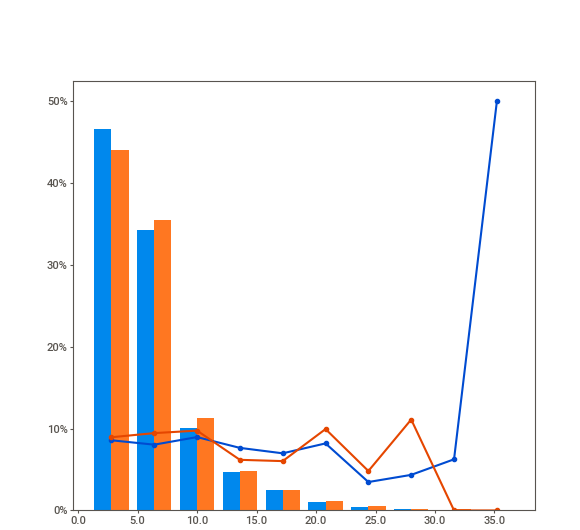
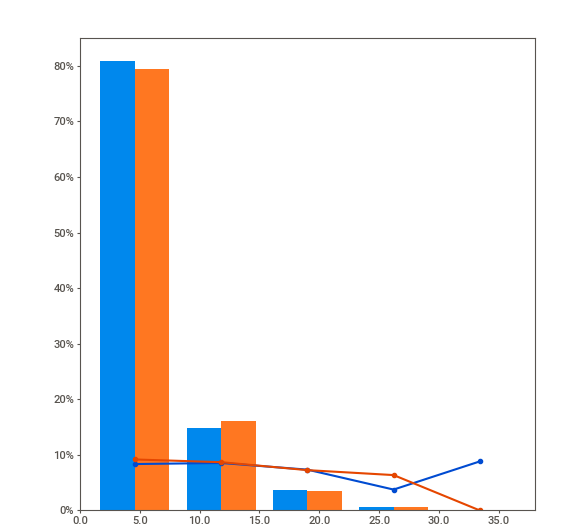
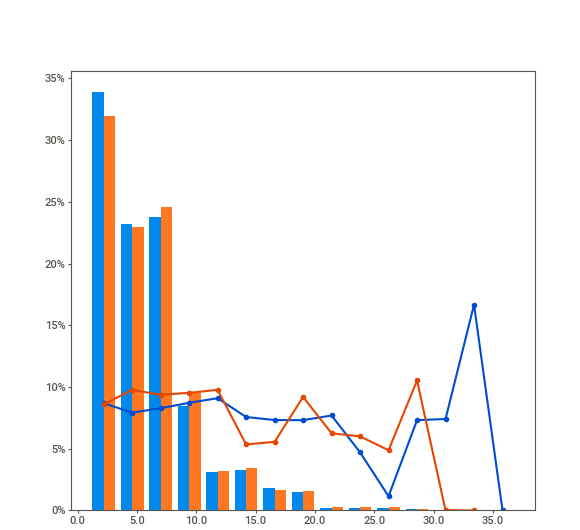
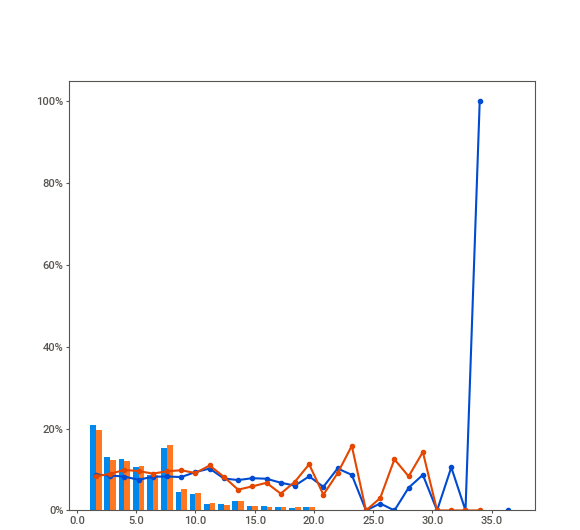
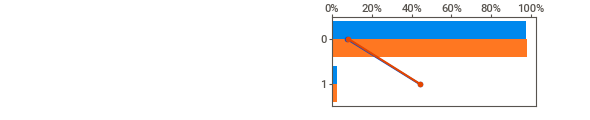
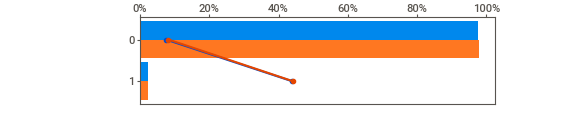
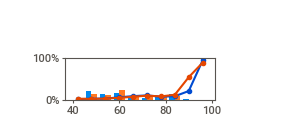
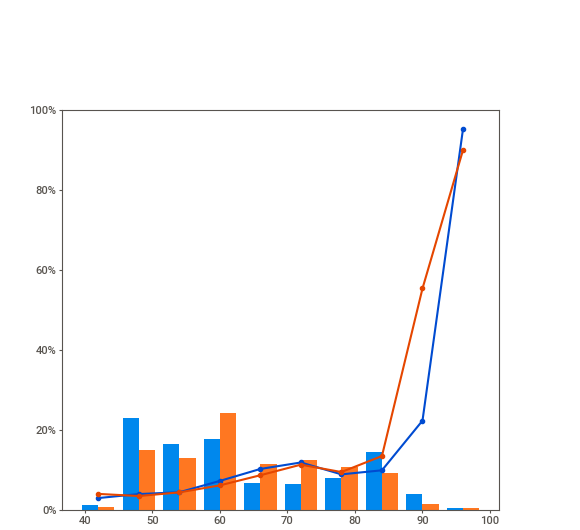
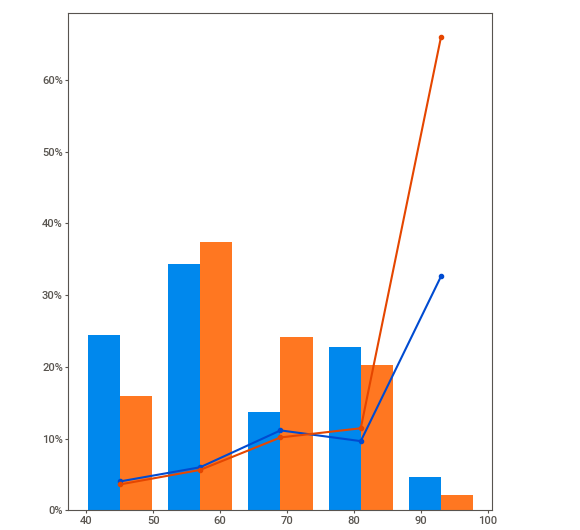
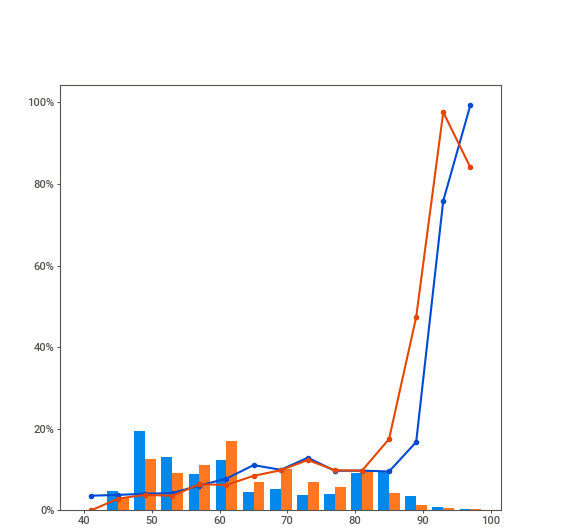
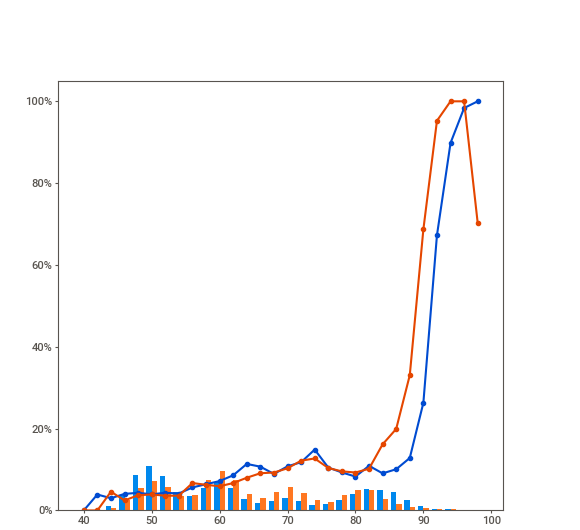
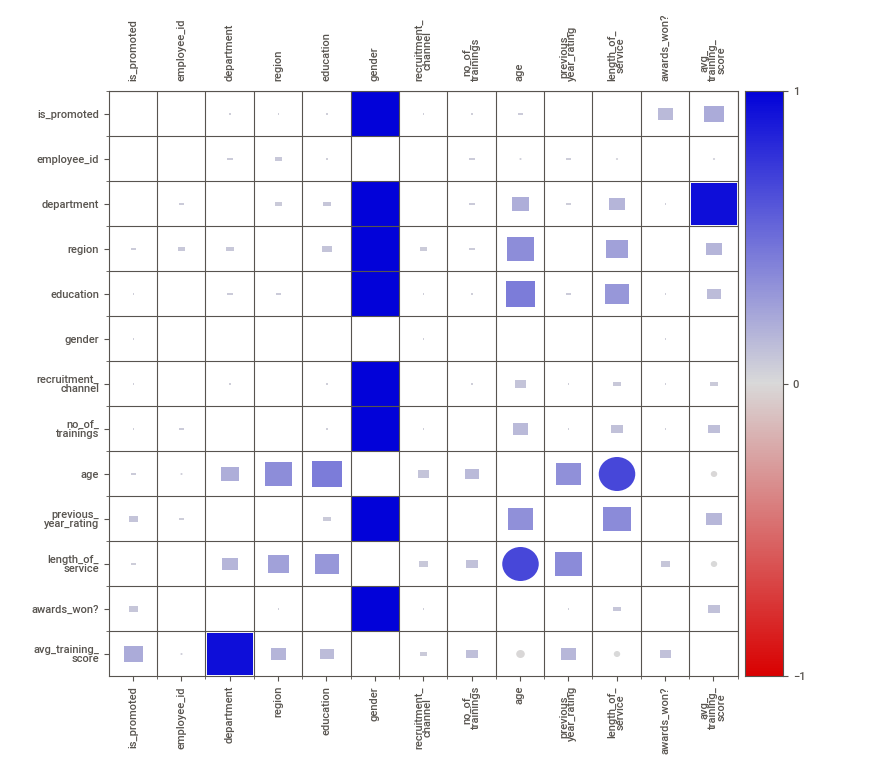
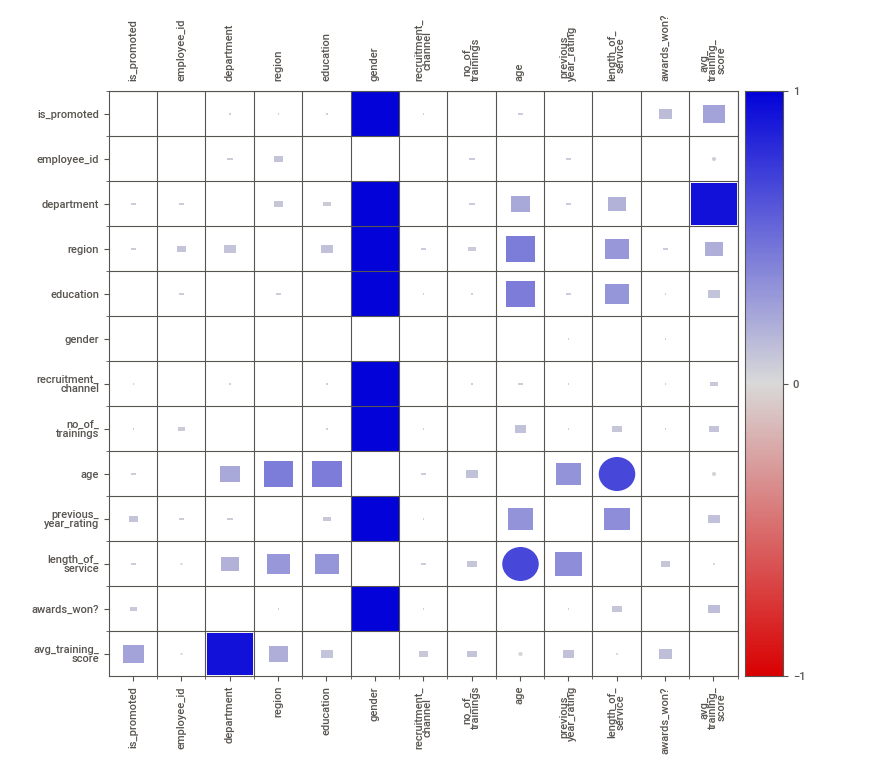

In [ ]:
# Genera el reporte con SweetViz
sweetv_compare_intra = sv.compare_intra(info,condition_series =
info['gender'] == 'm', names=['f', 'm'],
target_feat="is_promoted")
sweetv_compare_intra.show_notebook()

4. Elimina los registros con información faltante (`NaN`) y la columna `employee_id` por no tener aportación en la predicción.

In [ ]:
# Elimina faltantes
info_na = info.dropna()
info_na.head(4)

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0


In [ ]:
# Elimina la columna employee_id
info_depurada=info_na.drop('employee_id', axis=1)
info_depurada.head(4)

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0


5. Codifica las variables categóricas de info con `LabelEncoder`.

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
# Identifica las columnas categóricas automáticamente desde el DataFrame depurado
info_encoded = info_depurada.copy()
categorical_cols = info_depurada.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in categorical_cols:
    info_encoded[col] = le.fit_transform(info_encoded[col])
info_encoded.head(4)

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,7,31,2,0,2,1,35,5.0,8,0,49,0
1,4,14,0,1,0,1,30,5.0,4,0,60,0
2,7,10,0,1,2,1,34,3.0,7,0,50,0
3,7,15,0,1,0,2,39,1.0,10,0,50,0


6. Divide la matriz en conjuntos de entrenamiento y prueba (80:20), utilizando el parámetro `random_state=1` para garantizar reproducibilidad.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Divide el conjunto dataframe info para obtener: train y test
train_enc, test_enc = train_test_split(info_encoded, train_size=0.80, random_state=1)
print(train_enc, test_enc)

       department  region  education  gender  recruitment_channel  \
856             7       5          0       0                    2   
37928           0      31          0       1                    0   
23652           4      11          0       0                    2   
6705            4       4          0       1                    0   
13690           6      14          0       1                    2   
...           ...     ...        ...     ...                  ...   
49266           8      15          0       1                    0   
36688           8       7          0       0                    2   
5871            0      14          0       1                    2   
13722           7      15          0       1                    2   
37237           1      18          0       0                    2   

       no_of_trainings  age  previous_year_rating  length_of_service  \
856                  1   29                   4.0                  3   
37928                1   35

7. Observa la distribución de la variable objetivo `is_promoted`. En caso de que las clases estén desbalanceadas, realiza over_sampling con el método `SMOTE()`.

In [ ]:
# Observa la distribución
info_depurada['is_promoted'].value_counts()

,count
is_promoted,
0,44428
1,4232


In [ ]:
info_depurada['is_promoted'].value_counts(normalize=True) * 100

,proportion
is_promoted,
0,91.302918
1,8.697082


In [ ]:
# Separa los predictores (X) y la variable de salida (y)
y_target = 'is_promoted'
X_features = list(info_encoded.columns)
X_features.remove(y_target)

X_train = train_enc[X_features]
y_train = train_enc[y_target]

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
# Aplica SMOTE al conjunto de entrenamiento (train[X], train[y])
smote = SMOTE(random_state=1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Distribución original en entrenamiento:\n", y_train.value_counts())
print("\nDistribución después de SMOTE:\n", y_train_resampled.value_counts())

Distribución original en entrenamiento:
 is_promoted
0    35552
1     3376
Name: count, dtype: int64

Distribución después de SMOTE:
 is_promoted
0    35552
1    35552
Name: count, dtype: int64


8. Configura el autoaprendizaje de PyCaret asegurándote de usar `preprocess=False` para no aplicar ninguna operación adicional al conjunto.

In [ ]:
from pycaret.classification import *

In [ ]:
pyc = setup(data=train_balanced, target='is_promoted', test_data=test_enc, fold=10, preprocess=False, index=False, session_id=1)

,Description,Value
0,Session id,1
1,Target,is_promoted
2,Target type,Binary
3,Original data shape,"(80836, 12)"
4,Transformed data shape,"(80836, 12)"
5,Transformed train set shape,"(71104, 12)"
6,Transformed test set shape,"(9732, 12)"
7,Numeric features,11


9. Optimiza el mejor modelo `tune_model()` con la métrica `accuracy`.

In [ ]:
leader = compare_models(budget_time=1.5, fold=5)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.9488,0.9865,0.9407,0.9562,0.9465,0.8976,0.9005,5.8620
dt,Decision Tree Classifier,0.9162,0.9166,0.9382,0.8994,0.9166,0.8324,0.8363,0.3280
knn,K Neighbors Classifier,0.8746,0.9552,0.9899,0.8044,0.8875,0.7492,0.7699,1.5540
gbc,Gradient Boosting Classifier,0.8605,0.9352,0.8019,0.9077,0.8485,0.7210,0.7284,5.1880
ada,Ada Boost Classifier,0.8337,0.9122,0.7880,0.8669,0.8225,0.6675,0.6729,1.4960
qda,Quadratic Discriminant Analysis,0.6895,0.7641,0.7831,0.6598,0.7162,0.3789,0.3857,0.1300
lr,Logistic Regression,0.6859,0.7656,0.6954,0.6823,0.6887,0.3717,0.3720,4.2480
ridge,Ridge Classifier,0.6853,0.7650,0.6998,0.6800,0.6897,0.3706,0.3709,0.0660
nb,Naive Bayes,0.6817,0.7580,0.7676,0.6554,0.7070,0.3635,0.3690,0.1100
svm,SVM - Linear Kernel,0.6534,0.7606,0.7951,0.6345,0.6945,0.3068,0.3397,1.4940


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

In [ ]:
# Optimiza el mejor modelo
tuned_leader = tune_model(leader, optimize='Accuracy')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6425,0.7000,0.3401,0.8605,0.4875,0.2850,0.3578
1,0.8102,0.8694,0.6951,0.9028,0.7854,0.6203,0.6374
2,0.8092,0.8703,0.7028,0.8928,0.7865,0.6183,0.6329
3,0.7974,0.8609,0.6693,0.8998,0.7676,0.5947,0.6153
4,0.8156,0.8767,0.6954,0.9156,0.7904,0.6312,0.6503
5,0.8110,0.8673,0.6889,0.9114,0.7847,0.6219,0.6414
6,0.8104,0.8719,0.6897,0.9092,0.7844,0.6208,0.6397
7,0.8134,0.8726,0.6954,0.9102,0.7884,0.6267,0.6449
8,0.8060,0.8666,0.6906,0.8980,0.7807,0.6121,0.6291


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


10. Utiliza `evaluate_model()` para mostrar la interfaz de usuario con detalles del modelo optimizado y verifica las métricas `predict_model() `con el conjunto de prueba.

In [ ]:
# Detalles del modelo
evaluate_model(tuned_leader)
predict_model(tuned_leader)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9064,0.7685,0.3201,0.4544,0.3756,0.3266,0.3325


,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted,prediction_label,prediction_score
71104,7,11,2,1,2,1,42,4.0,5,0,49,0,0,0.9200
71105,4,11,0,1,0,1,30,1.0,2,0,55,0,0,1.0000
71106,8,11,0,1,2,1,27,5.0,5,0,80,0,1,0.8200
71107,4,19,0,0,0,1,35,1.0,3,0,55,0,0,1.0000
71108,7,20,0,1,2,1,36,3.0,4,0,49,0,0,0.9975
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80831,4,25,0,1,2,1,29,1.0,2,0,61,0,0,1.0000
80832,7,17,0,1,0,2,34,3.0,7,0,52,0,0,1.0000
80833,0,29,0,1,0,1,31,4.0,3,0,85,0,0,0.8500
80834,0,2,0,1,0,1,35,3.0,8,0,89,0,0,0.8200


In [ ]:
# Verifica las métricas
final_model = finalize_model(tuned_leader)
predict_model(final_model, data=test_enc)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9992,0.9998,0.9977,0.9930,0.9953,0.9949,0.9949


,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted,prediction_label,prediction_score
0,7,11,2,1,2,1,42,4.0,5,0,49,0,0,1.00
1,4,11,0,1,0,1,30,1.0,2,0,55,0,0,1.00
2,8,11,0,1,2,1,27,5.0,5,0,80,0,0,0.65
3,4,19,0,0,0,1,35,1.0,3,0,55,0,0,0.98
4,7,20,0,1,2,1,36,3.0,4,0,49,0,0,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9727,4,25,0,1,2,1,29,1.0,2,0,61,0,0,1.00
9728,7,17,0,1,0,2,34,3.0,7,0,52,0,0,0.99
9729,0,29,0,1,0,1,31,4.0,3,0,85,0,0,0.96
9730,0,2,0,1,0,1,35,3.0,8,0,89,0,0,0.95
